In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Load libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import folium

In [ ]:
# Load data
f_path = '/content/drive/MyDrive/earthquake_1995-2023.csv'
df = pd.read_csv(f_path)
print(df.head())

                                      title  magnitude         date_time  cdi  \
0          M 6.5 - 42 km W of Sola, Vanuatu        6.5  16-08-2023 12:47    7   
1  M 6.5 - 43 km S of Intipucá, El Salvador        6.5  19-07-2023 00:22    8   
2  M 6.6 - 25 km ESE of Loncopué, Argentina        6.6  17-07-2023 03:05    7   
3     M 7.2 - 98 km S of Sand Point, Alaska        7.2  16-07-2023 06:48    6   
4                  M 7.3 - Alaska Peninsula        7.3  16-07-2023 06:48    0   

   mmi   alert  tsunami  sig net  nst      dmin    gap magType    depth  \
0    4   green        0  657  us  114  7.177000   25.0     mww  192.955   
1    6  yellow        0  775  us   92  0.679000   40.0     mww   69.727   
2    5   green        0  899  us   70  1.634000   28.0     mww  171.371   
3    6   green        1  860  us  173  0.907000   36.0     mww   32.571   
4    5     NaN        1  820  at   79  0.879451  172.8      Mi   21.000   

   latitude  longitude               location      continent  

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   title      1000 non-null   object 
 1   magnitude  1000 non-null   float64
 2   date_time  1000 non-null   object 
 3   cdi        1000 non-null   int64  
 4   mmi        1000 non-null   int64  
 5   alert      449 non-null    object 
 6   tsunami    1000 non-null   int64  
 7   sig        1000 non-null   int64  
 8   net        1000 non-null   object 
 9   nst        1000 non-null   int64  
 10  dmin       1000 non-null   float64
 11  gap        1000 non-null   float64
 12  magType    1000 non-null   object 
 13  depth      1000 non-null   float64
 14  latitude   1000 non-null   float64
 15  longitude  1000 non-null   float64
 16  location   994 non-null    object 
 17  continent  284 non-null    object 
 18  country    651 non-null    object 
dtypes: float64(6), int64(5), object(8)
memory usage: 

In [ ]:
print(df.describe())

         magnitude          cdi         mmi      tsunami          sig  \
count  1000.000000  1000.000000  1000.00000  1000.000000  1000.000000   
mean      6.940150     3.605000     6.02700     0.325000   847.915000   
std       0.438148     3.328972     1.43399     0.468609   301.802632   
min       6.500000     0.000000     1.00000     0.000000   650.000000   
25%       6.600000     0.000000     5.00000     0.000000   691.000000   
50%       6.800000     4.000000     6.00000     0.000000   744.000000   
75%       7.100000     7.000000     7.00000     1.000000   874.250000   
max       9.100000     9.000000    10.00000     1.000000  2910.000000   

               nst         dmin          gap        depth     latitude  \
count  1000.000000  1000.000000  1000.000000  1000.000000  1000.000000   
mean    193.918000     1.125174    20.926290    74.612541     4.315554   
std     239.045858     2.073164    24.415895   130.812590    26.633320   
min       0.000000     0.000000     0.000000  

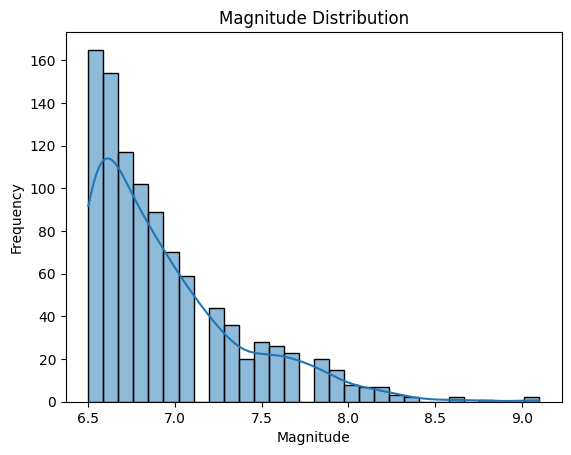

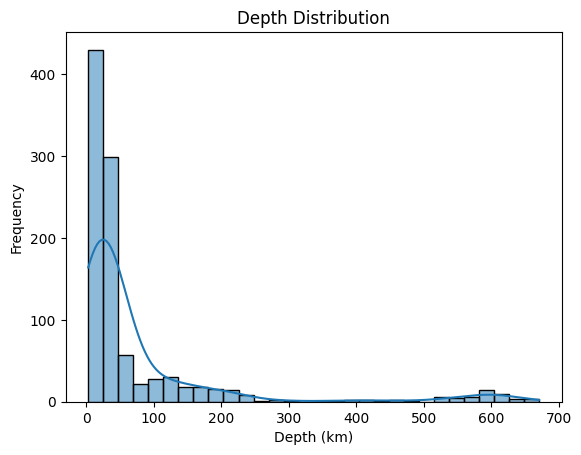

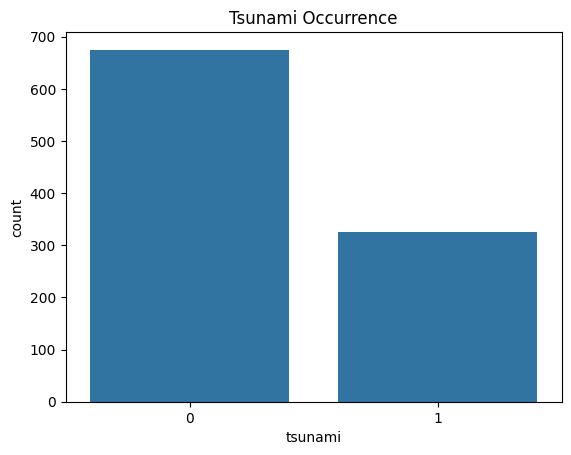

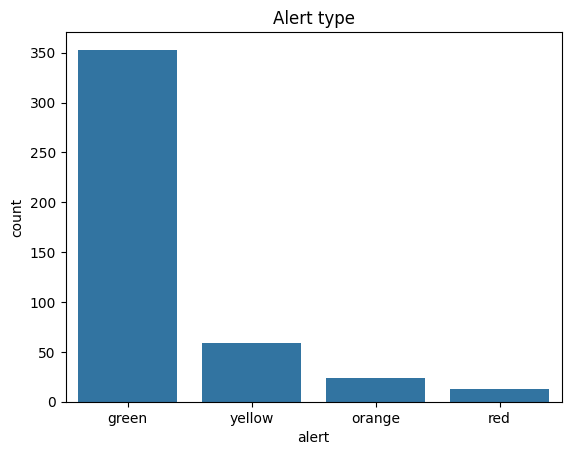

In [ ]:
plt.figure()
sns.histplot(df["magnitude"], bins=30, kde=True)
plt.title("Magnitude Distribution")
plt.xlabel("Magnitude")
plt.ylabel("Frequency")
plt.show()

plt.figure()
sns.histplot(df["depth"], bins=30, kde=True)
plt.title("Depth Distribution")
plt.xlabel("Depth (km)")
plt.ylabel("Frequency")
plt.show()

plt.figure()
sns.countplot(x="tsunami", data=df)
plt.title("Tsunami Occurrence")
plt.show()

plt.figure()
sns.countplot(x='alert', data=df)
plt.title('Alert type')
plt.show()

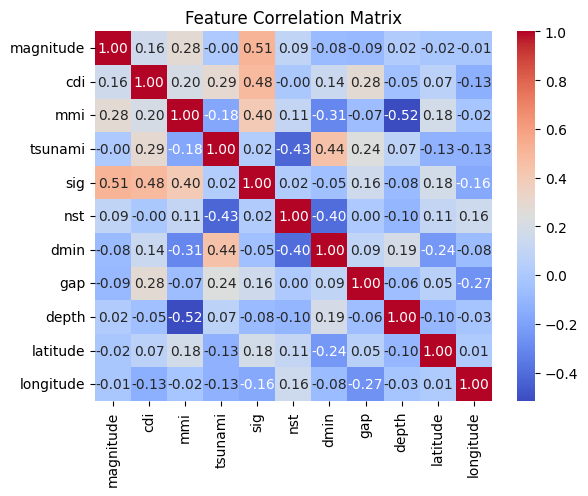

<Figure size 1000x600 with 0 Axes>

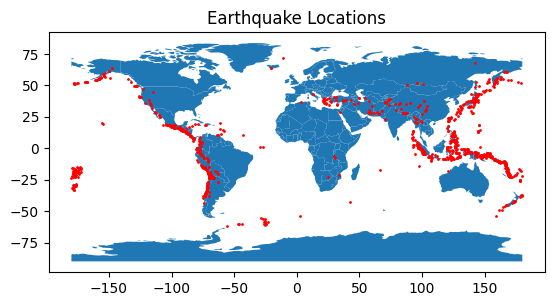

Interactive map saved.


In [ ]:
plt.figure()
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt = '.2f')
plt.title("Feature Correlation Matrix")
plt.show()



gdf = gpd.GeoDataFrame(df,geometry=gpd.points_from_xy(df.longitude, df.latitude),crs="EPSG:4326")

world = gpd.read_file("https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip")


plt.figure(figsize=(10, 6))
world.plot()
gdf.plot(ax=plt.gca(), markersize=1, color="red")
plt.title("Earthquake Locations")
plt.show()

map_center = [df["latitude"].mean(), df["longitude"].mean()]
m = folium.Map(location=map_center, zoom_start=2)

for _, row in df.iterrows():
    folium.CircleMarker(location=[row["latitude"], row["longitude"]],radius=row["magnitude"],
                        popup=f"Magnitude: {row['magnitude']}, location: {row['location']}",fill=True).add_to(m)

m.save("earthquake_map.html")

print("Interactive map saved.")

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

In [ ]:
f_path = "/content/drive/MyDrive/earthquake_1995-2023.csv"

In [ ]:
df = pd.read_csv(f_path)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   title      1000 non-null   object 
 1   magnitude  1000 non-null   float64
 2   date_time  1000 non-null   object 
 3   cdi        1000 non-null   int64  
 4   mmi        1000 non-null   int64  
 5   alert      449 non-null    object 
 6   tsunami    1000 non-null   int64  
 7   sig        1000 non-null   int64  
 8   net        1000 non-null   object 
 9   nst        1000 non-null   int64  
 10  dmin       1000 non-null   float64
 11  gap        1000 non-null   float64
 12  magType    1000 non-null   object 
 13  depth      1000 non-null   float64
 14  latitude   1000 non-null   float64
 15  longitude  1000 non-null   float64
 16  location   994 non-null    object 
 17  continent  284 non-null    object 
 18  country    651 non-null    object 
dtypes: float64(6), int64(5), object(8)
memory usage: 

In [ ]:
x = df.drop('alert', axis=1)
k = df.drop(['alert', 'tsunami'], axis = 1)
y = df['alert']
print(x.shape)
print(k.shape)
print(df.shape)

(1000, 18)
(1000, 17)
(1000, 19)


In [ ]:
xtrain, xtest, ytrain, ytest = train_test_split(x,y, test_size=0.2, random_state=43)

In [ ]:
numerical_data = xtrain.select_dtypes(include = ['int64', 'float64']).columns
categorical_data = xtrain.select_dtypes(include = ['object', 'category']).columns
print(categorical_data.shape)
print(numerical_data.shape)
print(df.columns.shape)

(7,)
(11,)
(19,)


In [ ]:
x = xtrain.columns
print(x)

Index(['title', 'magnitude', 'date_time', 'cdi', 'mmi', 'tsunami', 'sig',
       'net', 'nst', 'dmin', 'gap', 'magType', 'depth', 'latitude',
       'longitude', 'location', 'continent', 'country'],
      dtype='object')


In [ ]:
# Feature Engineering for skewed data
numerical_cdata = xtrain.select_dtypes(['int64', 'float64'])
for column in numerical_cdata.columns:
  if abs(numerical_cdata[column].skew()) > 1:
    numerical_cdata[column] = np.log1p(numerical_cdata[column])
    print(column)

magnitude
sig
dmin
gap
depth


In [ ]:
print(xtrain.select_dtypes(['int64', 'float64']))

     magnitude  cdi  mmi  tsunami   sig  nst   dmin   gap  depth  latitude  \
147        6.6    4    4        1   673    0  5.086  48.0  10.00  -18.5747   
88         7.2    9    8        1  2331    0  1.178  23.0  10.00   18.3521   
731        7.0    0    7        0   754  367  0.000  33.0  16.60   -3.6150   
741        7.0    0    5        0   754  568  0.000  61.2  10.00   37.8120   
36         6.9    4    4        0   735   99  2.229  34.0  25.00   -4.9559   
..         ...  ...  ...      ...   ...  ...    ...   ...    ...       ...   
277        7.2    6    5        1   799    0  4.823  14.0  16.37  -22.4765   
817        6.5    0    7        0   650  401  0.000   0.0  31.00   -4.2180   
255        6.9    6    4        1   742    0  2.495  13.0  12.00  -19.3733   
320        8.3    9    8        1  1960    0  0.684  19.0  22.44  -31.5729   
836        6.6    0    6        0   670  218  0.000   0.0  33.00  -12.0370   

     longitude  
147  -175.2720  
88    -73.4804  
731   135.53

In [ ]:
print(numerical_cdata)

     magnitude  cdi  mmi  tsunami       sig  nst      dmin       gap  \
147   2.028148    4    4        1  6.513230    0  1.805991  3.891820   
88    2.104134    9    8        1  7.754482    0  0.778407  3.178054   
731   2.079442    0    7        0  6.626718  367  0.000000  3.526361   
741   2.079442    0    5        0  6.626718  568  0.000000  4.130355   
36    2.066863    4    4        0  6.601230   99  1.172172  3.555348   
..         ...  ...  ...      ...       ...  ...       ...       ...   
277   2.104134    6    5        1  6.684612    0  1.761816  2.708050   
817   2.014903    0    7        0  6.478510  401  0.000000  0.000000   
255   2.066863    6    4        1  6.610696    0  1.251333  2.639057   
320   2.230014    9    8        1  7.581210    0  0.521172  2.995732   
836   2.028148    0    6        0  6.508769  218  0.000000  0.000000   

        depth  latitude  longitude  
147  2.397895  -18.5747  -175.2720  
88   2.397895   18.3521   -73.4804  
731  2.867899   -3.6150 

In [ ]:
from scipy.stats import skew

def log_transform_numpy(x):
  x = x.copy()
  # Identify skewed columns dynamically within the NumPy array
  # This assumes the order of numerical columns remains consistent after imputer
  for col_idx in range(x.shape[1]):
    # Check if column has enough non-NaN values to compute skew
    # and only apply log1p if skewness is significant
    if np.count_nonzero(~np.isnan(x[:, col_idx])) > 1 and abs(skew(x[:, col_idx][~np.isnan(x[:, col_idx])])) > 1:
      x[:, col_idx] = np.log1p(x[:, col_idx])
  return x

log_transformer = FunctionTransformer(log_transform_numpy)

In [ ]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", log_transformer),
    ("scaler", StandardScaler())
])

In [ ]:
numerical_cdata1 = xtrain.select_dtypes(['int64', 'float64'])
print(numerical_cdata)
print(numerical_cdata1.shape)

     magnitude  cdi  mmi  tsunami       sig  nst      dmin       gap  \
147   2.028148    4    4        1  6.513230    0  1.805991  3.891820   
88    2.104134    9    8        1  7.754482    0  0.778407  3.178054   
731   2.079442    0    7        0  6.626718  367  0.000000  3.526361   
741   2.079442    0    5        0  6.626718  568  0.000000  4.130355   
36    2.066863    4    4        0  6.601230   99  1.172172  3.555348   
..         ...  ...  ...      ...       ...  ...       ...       ...   
277   2.104134    6    5        1  6.684612    0  1.761816  2.708050   
817   2.014903    0    7        0  6.478510  401  0.000000  0.000000   
255   2.066863    6    4        1  6.610696    0  1.251333  2.639057   
320   2.230014    9    8        1  7.581210    0  0.521172  2.995732   
836   2.028148    0    6        0  6.508769  218  0.000000  0.000000   

        depth  latitude  longitude  
147  2.397895  -18.5747  -175.2720  
88   2.397895   18.3521   -73.4804  
731  2.867899   -3.6150 

In [ ]:
numeric_pipeline.fit(numerical_cdata1)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('log_transform',
                 FunctionTransformer(func=<function log_transform_numpy at 0x798c1dec04a0>)),
                ('scaler', StandardScaler())])

In [ ]:
numerical_data_transformed = numeric_pipeline.fit_transform(numerical_cdata1)

In [ ]:
numerical_data_transformed

array([[-0.80176094,  0.11521382, -1.42072725, ..., -1.0842076 ,
        -0.86634801, -1.91292739],
       [ 0.66678826,  1.61637111,  1.37873531, ..., -1.0842076 ,
         0.53453296, -1.04996709],
       [ 0.18956402, -1.08571201,  0.67886967, ..., -0.64007664,
        -0.29882634,  0.72203159],
       ...,
       [-0.05354107,  0.71567674, -1.42072725, ..., -0.92634948,
        -0.89664426,  1.06549779],
       [ 3.09962536,  1.61637111,  1.37873531, ..., -0.36930526,
        -1.35945683, -1.03465634],
       [-0.80176094, -1.08571201, -0.02099597, ..., -0.0178619 ,
        -0.61832924,  0.9840778 ]])

In [ ]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [ ]:
# Select categorical columns from training data
categorical_cols = xtrain.select_dtypes(include=['object', 'category']).columns

# Extract only categorical training data
categorical_train = xtrain[categorical_cols]

# Fit the categorical pipeline on training data
categorical_pipeline.fit(categorical_train)

# Transform training data
categorical_train_transformed = categorical_pipeline.transform(categorical_train)

# Transform test data (important for evaluation)
categorical_test = xtest[categorical_cols]
categorical_test_transformed = categorical_pipeline.transform(categorical_test)

# Convert transformed output to array (if sparse matrix)
categorical_train_transformed = categorical_train_transformed.toarray()
categorical_test_transformed = categorical_test_transformed.toarray()

# Get feature names after OneHotEncoding
encoded_feature_names = categorical_pipeline.named_steps["encoder"].get_feature_names_out(categorical_cols)

# Convert to DataFrame for better readability
categorical_train_df = pd.DataFrame(
    categorical_train_transformed,
    columns=encoded_feature_names,
    index=xtrain.index
)

categorical_test_df = pd.DataFrame(
    categorical_test_transformed,
    columns=encoded_feature_names,
    index=xtest.index
)

print("Categorical encoding completed.")
print("Encoded training shape:", categorical_train_df.shape)
print("Encoded test shape:", categorical_test_df.shape)

Categorical encoding completed.
Encoded training shape: (800, 2096)
Encoded test shape: (200, 2096)


In [ ]:
# Remove duplicate rows
df = df.drop_duplicates()
# Remove duplicate columns if any
df = df.loc[:, ~df.columns.duplicated()]

print("Shape after removing duplicates: ", df.shape)

Shape after removing duplicates:  (1000, 19)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LogisticRegression, LinearRegression, LogisticRegressionCV
from sklearn.metrics import classification_report,mean_absolute_error, mean_squared_error, r2_score, accuracy_score, confusion_matrix
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/earthquake_1995-2023.csv')

In [ ]:
df['datetime'] = pd.to_datetime(df['date_time'])
df['daytime'] = df['datetime'].dt.hour.apply(lambda x: 'Morning' if 5<=x<=10 else 'Afternoon' if 11<x<=15 else 'Evening' if 16<=x<=19 else 'Night')

/tmp/ipykernel_2349/4006721469.py:1: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['datetime'] = pd.to_datetime(df['date_time'])


In [ ]:
def getseason(month):
  if month in [12, 1, 2]:
    return 'Winter'
  elif month in [3, 4, 5]:
    return 'Spring'
  elif month in [6, 7, 8]:
    return 'Summer'
  else:
    return 'Autumn'
  df['season'] = df['datetime'].dt.month.apply(getseason)

In [ ]:
x = df.drop(['title', 'date_time', 'location', 'continent', 'country', 'datetime', 'magnitude'], axis=1)
y = df['magnitude']

In [ ]:
x_n = x.select_dtypes(['float64', 'int64'])
x_c = x.select_dtypes('object')
print(x_c.columns)

Index(['alert', 'net', 'magType', 'daytime'], dtype='object')


In [ ]:
print(x_n.columns)

Index(['cdi', 'mmi', 'tsunami', 'sig', 'nst', 'dmin', 'gap', 'depth',
       'latitude', 'longitude'],
      dtype='object')


In [ ]:
from scipy.stats import skew
def log_transform1(x):
  for column in range(x.shape[1]):
    if abs(skew(x[:,column])) > 1:
      x[:,column] = np.log1p(x[:,column])
    return x
log_transformer = FunctionTransformer(log_transform1)

In [ ]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", log_transformer),
    ("scaler", StandardScaler())
])

In [ ]:
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy = 'most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown = 'ignore'))
])

In [ ]:
preprocess = ColumnTransformer(
    transformers = [
        ('numerical', numeric_pipeline, x_n.columns),
        ('categorical', categorical_pipeline, x_c.columns)
    ]
)

In [ ]:
f0 = Pipeline(
    steps = [
        ('preprocess', preprocess),
        ('model0', LinearRegression)
    ]
)

In [ ]:
f1 = Pipeline(
    steps = [
        ('preprocess', preprocess),
        ('model1', LogisticRegression()) # Instantiate the model
    ]
)

In [ ]:
f2 = Pipeline(
    steps = [
        ('preprocess', preprocess),
        ('model2', LogisticRegression(multi_class = 'ovr'))
    ]
)

In [ ]:
f3 = Pipeline(
    steps = [
        ('preprocess', preprocess),
        ('model3', LogisticRegressionCV(cv = 5))
    ]
)

In [ ]:
f4 = Pipeline(
    steps = [
        ('preprocess', preprocess),
        ('model4', DecisionTreeRegressor(max_depth = 5, random_state=42))
    ]
)

In [ ]:
f5 = Pipeline(
    steps = [
        ('preprocess', preprocess),
        ('model5', DecisionTreeClassifier(max_depth = 5, criterion='gini', random_state=42))
    ]
)

In [ ]:
f0 = Pipeline(
    steps = [
        ('preprocess', preprocess),
        ('model0', LinearRegression()) # Instantiate the model
    ]
)
xtrain,xtest,ytrain,ytest = train_test_split(x,y, test_size = 0.2, random_state = 40)
f0.fit(xtrain, ytrain)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log_transform',
                                                                   FunctionTransformer(func=<function log_transform1 at 0x798c1db172e0>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['cdi', 'mmi', 'tsunami', 'sig', 'nst', 'dmin', 'gap', 'depth',
       'latitude', 'longitude'],
      dtype='object')),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['alert', 'net', 'magType', 'daytime'], dtype='object'))])),
                ('model0', LinearRegression())])

In [ ]:
predictions = f0.predict(xtest)
mae = mean_absolute_error(ytest, predictions)
mse = mean_squared_error(ytest, predictions)
r2score = r2_score(ytest, predictions)
print(mae, mse, r2score)

0.23618192561818824 0.10196965867835214 0.3896143179328577


In [ ]:
df['magnitude_class'] = pd.qcut(df['magnitude'], q=3, labels=['Low', 'Medium', 'High'])

In [ ]:
yc = df['magnitude_class']

In [ ]:
xtrain,xtest,ytrain,ytest = train_test_split(x,yc, test_size = 0.2, random_state = 40)
f1.fit(xtrain, ytrain)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log_transform',
                                                                   FunctionTransformer(func=<function log_transform1 at 0x798c1db172e0>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['cdi', 'mmi', 'tsunami', 'sig', 'nst', 'dmin', 'gap', 'depth',
       'latitude', 'longitude'],
      dtype='object')),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['alert', 'net', 'magType', 'daytime'], dtype='object'))])),
                ('model1', LogisticRegression())])

In [ ]:
predictions = f1.predict(xtest)
print(accuracy_score(ytest, predictions), '\n', classification_report(ytest, predictions), '\n', confusion_matrix(ytest, predictions))

0.635 
               precision    recall  f1-score   support

        High       0.70      0.72      0.71        58
         Low       0.65      0.90      0.75        86
      Medium       0.36      0.14      0.21        56

    accuracy                           0.64       200
   macro avg       0.57      0.59      0.56       200
weighted avg       0.59      0.64      0.59       200
 
 [[42  5 11]
 [ 6 77  3]
 [12 36  8]]


In [ ]:
pred_prob = f1.predict_proba(xtest)

In [ ]:
f2.fit(xtrain, ytrain)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log_transform',
                                                                   FunctionTransformer(func=<function log_transform1 at 0x798c1db172e0>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['cdi', 'mmi', 'tsunami', 'sig', 'nst', 'dmin', 'gap', 'depth',
       'latitude', 'longitude'],
      dtype='object')),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['alert', 'net', 'magType', 'daytime'], dtype='object'))])),
                ('model2', LogisticRegression(multi_class='ovr'))])

In [ ]:
predictions = f2.predict(xtest)
print(accuracy_score(ytest, predictions), '\n', classification_report(ytest, predictions), '\n', confusion_matrix(ytest, predictions))

0.62 
               precision    recall  f1-score   support

        High       0.70      0.72      0.71        58
         Low       0.61      0.91      0.73        86
      Medium       0.31      0.07      0.12        56

    accuracy                           0.62       200
   macro avg       0.54      0.57      0.52       200
weighted avg       0.55      0.62      0.55       200
 
 [[42  8  8]
 [ 7 78  1]
 [11 41  4]]


In [ ]:
predictions = f2.predict(xtrain)
print(accuracy_score(ytrain, predictions),'\n',classification_report(ytrain, predictions),'\n',confusion_matrix(ytrain, predictions))

0.67625 
               precision    recall  f1-score   support

        High       0.77      0.77      0.77       245
         Low       0.65      0.94      0.77       350
      Medium       0.49      0.11      0.18       205

    accuracy                           0.68       800
   macro avg       0.64      0.61      0.57       800
weighted avg       0.65      0.68      0.62       800
 
 [[188  37  20]
 [ 16 330   4]
 [ 40 142  23]]


In [ ]:
f3.fit(xtrain, ytrain)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log_transform',
                                                                   FunctionTransformer(func=<function log_transform1 at 0x798c1db172e0>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['cdi', 'mmi', 'tsunami', 'sig', 'nst', 'dmin', 'gap', 'depth',
       'latitude', 'longitude'],
      dtype='object')),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['alert', 'net', 'magType', 'daytime'], dtype='object'))])),
                ('model3', LogisticRegressionCV(cv=5))])

In [ ]:
predictions = f3.predict(xtest)
print(accuracy_score(ytest, predictions),'\n',classification_report(ytest, predictions),'\n',confusion_matrix(ytest, predictions))

0.62 
               precision    recall  f1-score   support

        High       0.68      0.71      0.69        58
         Low       0.66      0.87      0.75        86
      Medium       0.30      0.14      0.19        56

    accuracy                           0.62       200
   macro avg       0.55      0.57      0.55       200
weighted avg       0.57      0.62      0.58       200
 
 [[41  3 14]
 [ 6 75  5]
 [13 35  8]]


In [ ]:
predictions = f3.predict(xtrain)
print(accuracy_score(ytrain, predictions),'\n',classification_report(ytrain, predictions),'\n',confusion_matrix(ytrain, predictions))

0.71125 
               precision    recall  f1-score   support

        High       0.79      0.77      0.78       245
         Low       0.72      0.93      0.81       350
      Medium       0.51      0.27      0.36       205

    accuracy                           0.71       800
   macro avg       0.67      0.66      0.65       800
weighted avg       0.69      0.71      0.68       800
 
 [[189  13  43]
 [ 15 324  11]
 [ 35 114  56]]


In [ ]:
xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.2, random_state=42)
f4.fit(xtrain, ytrain)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log_transform',
                                                                   FunctionTransformer(func=<function log_transform1 at 0x798c1db172e0>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['cdi', 'mmi', 'tsunami', 'sig', 'nst', 'dmin', 'gap', 'depth',
       'latitude', 'longitude'],
      dtype='object')),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['alert', 'net', 'magType', 'daytime'], dtype='object'))])),
                ('model4',
                 DecisionTreeRegressor(max_depth=5, random_state=42))])

In [ ]:
predictions = f4.predict(xtest)
mae = mean_absolute_error(ytest, predictions)
mse = mean_squared_error(ytest, predictions)
r2score = r2_score(ytest, predictions)
print(mae, mse, r2score)

0.11514339854492386 0.04790027918181408 0.7548349858067989


In [ ]:
predictions = f4.predict(xtrain)
mae = mean_absolute_error(ytrain, predictions)
mse = mean_squared_error(ytrain, predictions)
r2score = r2_score(ytrain, predictions)
print(mae, mse, r2score)

0.11640731132305542 0.04956493064719914 0.7403253741612028


In [ ]:
xtrain,xtest,ytrain,ytest = train_test_split(x,yc, test_size = 0.2, random_state = 40)
f5.fit(xtrain, ytrain)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log_transform',
                                                                   FunctionTransformer(func=<function log_transform1 at 0x798c1db172e0>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['cdi', 'mmi', 'tsunami', 'sig', 'nst', 'dmin', 'gap', 'depth',
       'latitude', 'longitude'],
      dtype='object')),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['alert', 'net', 'magType', 'daytime'], dtype='object'))])),
                ('model5',
                 DecisionTreeClassifier(max_depth=5, random_state=42))])

In [ ]:
predictions = f5.predict(xtest)
print(accuracy_score(ytest, predictions), '\n', classification_report(ytest, predictions), '\n', confusion_matrix(ytest, predictions))

0.82 
               precision    recall  f1-score   support

        High       0.71      0.93      0.81        58
         Low       0.94      0.86      0.90        86
      Medium       0.80      0.64      0.71        56

    accuracy                           0.82       200
   macro avg       0.82      0.81      0.81       200
weighted avg       0.83      0.82      0.82       200
 
 [[54  0  4]
 [ 7 74  5]
 [15  5 36]]


In [ ]:
predictions = f5.predict(xtrain)
print(accuracy_score(ytrain, predictions), '\n', classification_report(ytrain, predictions), '\n', confusion_matrix(ytrain, predictions))

0.87625 
               precision    recall  f1-score   support

        High       0.78      0.93      0.85       245
         Low       0.98      0.89      0.93       350
      Medium       0.85      0.79      0.82       205

    accuracy                           0.88       800
   macro avg       0.87      0.87      0.87       800
weighted avg       0.89      0.88      0.88       800
 
 [[229   2  14]
 [ 25 310  15]
 [ 39   4 162]]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LogisticRegression, LinearRegression, LogisticRegressionCV
from sklearn.metrics import classification_report,mean_absolute_error, mean_squared_error, r2_score, accuracy_score, confusion_matrix
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score, GridSearchCV

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/earthquake_1995-2023.csv')

In [ ]:
from scipy.stats import skew
def log_transform1(x):
  x = x.copy()
  for column in range(x.shape[1]):
    if abs(skew(x[:,column])) > 1:
      x[:,column] = np.log1p(x[:,column])
  return x
log_transformer = FunctionTransformer(log_transform1, feature_names_out='one-to-one')

In [ ]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", log_transformer),
    ("scaler", StandardScaler())
])

In [ ]:
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy = 'most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown = 'ignore'))
])

In [ ]:
preprocess = ColumnTransformer(
    transformers = [
        ('numerical', numeric_pipeline, x_n.columns),
        ('categorical', categorical_pipeline, x_c.columns)
    ]
)

In [ ]:
am1 = Pipeline(
    steps = [
        ('preprocess', preprocess),
        ('random forest', RandomForestRegressor(
        n_estimators=100,
        max_depth=3,
        random_state=39,
        n_jobs=-1))
        ]
)

In [ ]:
am2 = Pipeline(
    steps = [
        ('preprocess', preprocess),
        ('gradient boosting', GradientBoostingRegressor(
        n_estimators=100,
        max_depth=3,
        random_state=3))
        ]
)

In [ ]:
am3 = Pipeline(
    steps = [
        ('preprocess', preprocess),
        ('xgboost', XGBRegressor(
        n_estimators=100,
        max_depth=3,
        random_state=39,
        n_jobs=-1))
        ]
)

In [ ]:
am4 = Pipeline(
    steps = [
        ('preprocess', preprocess),
        ('histgradient boosting', HistGradientBoostingRegressor(
        max_depth=3,
        max_iter=100,
        random_state=39))
        ]
)

In [ ]:
xtrain,xtest,ytrain,ytest = train_test_split(x,y, test_size = 0.2, random_state = 40)
am1.fit(xtrain, ytrain)
am2.fit(xtrain, ytrain)
am3.fit(xtrain, ytrain)
am4.fit(xtrain, ytrain)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log_transform',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<function log_transform1 at 0x798c1db177e0>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['cdi', 'mmi', 'tsunami', 'sig', 'nst', 'dmin', 'gap', 'depth',
       'latitude', 'longitude'],
      dtype='object')),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['alert', 'net', 'magType', 'daytime'], dtype='object'))])),
                ('histgradient boosting',
                 HistGradientBoostingRegressor(max_depth=3, random_state=39))])

In [ ]:
predictions1 = am1.predict(xtest)
mae1 = mean_absolute_error(ytest, predictions1)
mse = mean_squared_error(ytest, predictions1)
r2score1 = r2_score(ytest, predictions1)
print(mse, mae1, r2score1)

0.06724274033553654 0.15104174042512183 0.5974880522721242


In [ ]:
predictions2 = am2.predict(xtest)
mae2 = mean_absolute_error(ytest, predictions2)
mse = mean_squared_error(ytest, predictions2)
r2score2 = r2_score(ytest, predictions2)
print(mse, mae2, r2score2)

0.03765740468243958 0.11051540002624206 0.774584509354163


In [ ]:
predictions3 = am3.predict(xtest)
mae3 = mean_absolute_error(ytest, predictions3)
mse = mean_squared_error(ytest, predictions3)
r2score3 = r2_score(ytest, predictions3)
print(mse, mae3, r2score3)

0.04230939640239285 0.11767542266845704 0.74673790110071


In [ ]:
predictions4 = am4.predict(xtest)
mae4 = mean_absolute_error(ytest, predictions4)
mse = mean_squared_error(ytest, predictions4)
r2score4 = r2_score(ytest, predictions4)
print(mse, mae4, r2score4)

0.04733524707091043 0.12608504642921037 0.716653390393978


In [ ]:
predictions1 = am1.predict(xtrain)
mae1 = mean_absolute_error(ytrain, predictions1)
mse = mean_squared_error(ytrain, predictions1)
r2score1 = r2_score(ytrain, predictions1)
print(mse, mae1, r2score1)

0.0588871944625265 0.14353653904496524 0.7024986892305339


In [ ]:
predictions2 = am2.predict(xtrain)
mae2 = mean_absolute_error(ytrain, predictions2)
mse = mean_squared_error(ytrain, predictions2)
r2score2 = r2_score(ytrain, predictions2)
print(mse, mae2, r2score2)

0.015627483899601 0.07648648674744148 0.9210491009701848


In [ ]:
predictions3 = am3.predict(xtrain)
mae3 = mean_absolute_error(ytrain, predictions3)
mse = mean_squared_error(ytrain, predictions3)
r2score3 = r2_score(ytrain, predictions3)
print(mse, mae3, r2score3)

0.00466182295906623 0.04628057026863098 0.9764482167378519


In [ ]:
predictions4 = am4.predict(xtrain)
mae4 = mean_absolute_error(ytrain, predictions4)
mse = mean_squared_error(ytrain, predictions4)
r2score4 = r2_score(ytrain, predictions4)
print(mse, mae4, r2score4)

0.022844547285786866 0.09072096473888693 0.884588104026903


In [ ]:
print('---------------------Cross Validation-------------------------')
scores10 = cross_val_score(am1, xtrain, ytrain, cv=5, scoring='r2')
scores11 = cross_val_score(am1, xtrain, ytrain,cv=5,scoring='neg_mean_absolute_error')
print("R2 scores model 1(random forest):", scores10)
print("Mean R2 model 1(random forest):", scores10.mean())
print("MAE model 1(random forest):", scores11*-1)
print("Mean MAE model 1(random forest):", scores11.mean()*-1)
print('---------------------xxxxxxxxxxxxxxxx-------------------------')
scores20 = cross_val_score(am2, xtrain, ytrain, cv=5, scoring='r2')
scores21 = cross_val_score(am2, xtrain, ytrain,cv=5,scoring='neg_mean_absolute_error')
print("R2 scores model 2(gradient boosting):", scores20)
print("Mean R2 model 2(gradient boosting):", scores20.mean())
print("MAE model 2(gradient boosting):", scores21*-1)
print("Mean MAE model 2(gradient boosting):", scores21.mean()*-1)
print('---------------------xxxxxxxxxxxxxxxx-------------------------')
scores30 = cross_val_score(am3, xtrain, ytrain, cv=5, scoring='r2')
scores31 = cross_val_score(am3, xtrain, ytrain,cv=5,scoring='neg_mean_absolute_error')
print("R2 scores model 3(xgboost):", scores30)
print("Mean R2 model 3(xgboost):", scores30.mean())
print("MAE model 3(xgboost):", scores31*-1)
print("Mean MAE model 3(xgboost):", scores31.mean()*-1)
print('---------------------xxxxxxxxxxxxxxxx-------------------------')
scores40 = cross_val_score(am4, xtrain, ytrain, cv=5, scoring='r2')
scores41 = cross_val_score(am4, xtrain, ytrain,cv=5,scoring='neg_mean_absolute_error')
print("R2 scores model 4(hist gradient boosting):", scores40)
print("Mean R2 model 4(hist gradient boosting):", scores40.mean())
print("MAE model 4(hist gradient boosting):", scores41*-1)
print("Mean MAE model 4(hist gradient boosting):", scores41.mean()*-1)

---------------------Cross Validation-------------------------
R2 scores model 1(random forest): [0.67141996 0.56491844 0.66587546 0.80184009 0.61355306]
Mean R2 model 1(random forest): 0.6635214026385747
MAE model 1(random forest): [0.15967264 0.16168044 0.1475483  0.1151069  0.18025569]
Mean MAE model 1(random forest): 0.15285279493885467
---------------------xxxxxxxxxxxxxxxx-------------------------
R2 scores model 2(gradient boosting): [0.77162631 0.72336953 0.80292769 0.88243018 0.73128047]
Mean R2 model 2(gradient boosting): 0.7823268373703952
MAE model 2(gradient boosting): [0.12477678 0.12496452 0.10786125 0.08991173 0.13908896]
Mean MAE model 2(gradient boosting): 0.11732064586677042
---------------------xxxxxxxxxxxxxxxx-------------------------
R2 scores model 3(xgboost): [0.80228357 0.75604915 0.82202553 0.83024522 0.73403342]
Mean R2 model 3(xgboost): 0.7889273775438186
MAE model 3(xgboost): [0.12057978 0.12152022 0.10438602 0.10636158 0.13807238]
Mean MAE model 3(xgboost):

In [ ]:
param1 = {
    'random forest__n_estimators' : [50, 100, 150],
    'random forest__max_depth': [3, 5, 10],
    'random forest__max_features': [1.0, 'sqrt', 'log2']
}
param2 = {
    'gradient boosting__n_estimators': [20, 50, 100],
    'gradient boosting__learning_rate': [0.01, 0.1],
    'gradient boosting__max_depth': [1, 3]
}
param3 = {
    'xgboost__n_estimators': [20, 50, 100],
    'xgboost__learning_rate': [0.01, 0.1],
    'xgboost__max_depth': [1, 2, 3]
}
param4 = {
    'histgradient boosting__max_iter': [20, 50, 100],
    'histgradient boosting__learning_rate': [0.01, 0.1],
    'histgradient boosting__max_depth': [1, 3, 5]
}
scoring_metric = {
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2'
}

In [ ]:
grid_search1 = GridSearchCV(estimator=am1, param_grid=param1, cv=5, scoring=scoring_metric, refit = 'MAE',n_jobs=-1)
grid_search1.fit(xtrain, ytrain)
print(f"Best Params (via MAE): {grid_search1.best_params_}")
print(f"Best MAE Score: {-grid_search1.best_score_}")
best_index1 = grid_search1.best_index_
best_r21 = grid_search1.cv_results_['mean_test_R2'][best_index1]
print(f"Associated R2 Score: {best_r21}")

Best Params (via MAE): {'random forest__max_depth': 10, 'random forest__max_features': 1.0, 'random forest__n_estimators': 150}
Best MAE Score: 0.11080418544998341
Associated R2 Score: 0.7710542706897522


In [ ]:
grid_search2 = GridSearchCV(estimator=am2, param_grid=param2, cv=5, scoring=scoring_metric, refit = 'MAE',n_jobs=-1)
grid_search2.fit(xtrain, ytrain)
print(f"Best Params (via MAE): {grid_search2.best_params_}")
print(f"Best MAE Score: {-grid_search2.best_score_}")
best_index2 = grid_search2.best_index_
best_r22 = grid_search2.cv_results_['mean_test_R2'][best_index2]
print(f"Associated R2 Score: {best_r22}")

Best Params (via MAE): {'gradient boosting__learning_rate': 0.1, 'gradient boosting__max_depth': 3, 'gradient boosting__n_estimators': 100}
Best MAE Score: 0.11732064586677042
Associated R2 Score: 0.7823268373703952


In [ ]:
grid_search3 = GridSearchCV(estimator=am3, param_grid=param3, cv=5, scoring=scoring_metric, refit = 'MAE',n_jobs=-1)
grid_search3.fit(xtrain, ytrain)
print(f"Best Params (via MAE): {grid_search3.best_params_}")
print(f"Best MAE Score: {-grid_search3.best_score_}")
best_index3 = grid_search3.best_index_
best_r23 = grid_search3.cv_results_['mean_test_R2'][best_index3]
print(f"Associated R2 Score: {best_r23}")

Best Params (via MAE): {'xgboost__learning_rate': 0.1, 'xgboost__max_depth': 3, 'xgboost__n_estimators': 100}
Best MAE Score: 0.11900098493099212
Associated R2 Score: 0.7791014664637697


In [ ]:
grid_search4 = GridSearchCV(estimator=am4, param_grid=param4, cv=5, scoring=scoring_metric, refit = 'MAE',n_jobs=-1)
grid_search4.fit(xtrain, ytrain)
print(f"Best Params (via MAE): {grid_search4.best_params_}")
print(f"Best MAE Score: {-grid_search4.best_score_}")
best_index4 = grid_search4.best_index_
best_r24 = grid_search4.cv_results_['mean_test_R2'][best_index4]
print(f"Associated R2 Score: {best_r24}")

Best Params (via MAE): {'histgradient boosting__learning_rate': 0.1, 'histgradient boosting__max_depth': 5, 'histgradient boosting__max_iter': 100}
Best MAE Score: 0.1183974712719035
Associated R2 Score: 0.7509320349628563


In [ ]:
grid_pred1 = grid_search1.predict(xtest)
test_r2 = r2_score(ytest, grid_pred1)
print(f"Grid Search Test MAE: {mean_absolute_error(ytest, grid_pred1)}")
print(f'Grid Search Test r2 score: {test_r2}')
grid_pred1 = grid_search1.predict(xtrain)
train_r2 = r2_score(ytrain, grid_pred1)
print(f"Grid Search Train MAE: {mean_absolute_error(ytrain, grid_pred1)}")
print(f'Grid Search Train r2 score: {train_r2}')

Grid Search Test MAE: 0.09717959534704323
Grid Search Test r2 score: 0.7917920298349629
Grid Search Train MAE: 0.048852201835996235
Grid Search Train r2 score: 0.9526878971890731


In [ ]:
grid_pred1 = grid_search2.predict(xtest)
test_r2 = r2_score(ytest, grid_pred1)
print(f"Grid Search Test MAE: {mean_absolute_error(ytest, grid_pred1)}")
print(f'Grid Search Test r2 score: {test_r2}')
grid_pred1 = grid_search2.predict(xtrain)
train_r2 = r2_score(ytrain, grid_pred1)
print(f"Grid Search Train MAE: {mean_absolute_error(ytrain, grid_pred1)}")
print(f'Grid Search Train r2 score: {train_r2}')

Grid Search Test MAE: 0.11051540002624206
Grid Search Test r2 score: 0.774584509354163
Grid Search Train MAE: 0.07648648674744148
Grid Search Train r2 score: 0.9210491009701848


In [ ]:
grid_pred1 = grid_search3.predict(xtest)
test_r2 = r2_score(ytest, grid_pred1)
print(f"Grid Search Test MAE: {mean_absolute_error(ytest, grid_pred1)}")
print(f'Grid Search Test r2 score: {test_r2}')
grid_pred1 = grid_search3.predict(xtrain)
train_r2 = r2_score(ytrain, grid_pred1)
print(f"Grid Search Train MAE: {mean_absolute_error(ytrain, grid_pred1)}")
print(f'Grid Search Train r2 score: {train_r2}')

Grid Search Test MAE: 0.11413614273071289
Grid Search Test r2 score: 0.7608803853058101
Grid Search Train MAE: 0.08161666011810303
Grid Search Train r2 score: 0.9069273025762196


In [ ]:
import joblib

joblib.dump(grid_search1, 'random_forest_model.pkl')

['random_forest_model.pkl']

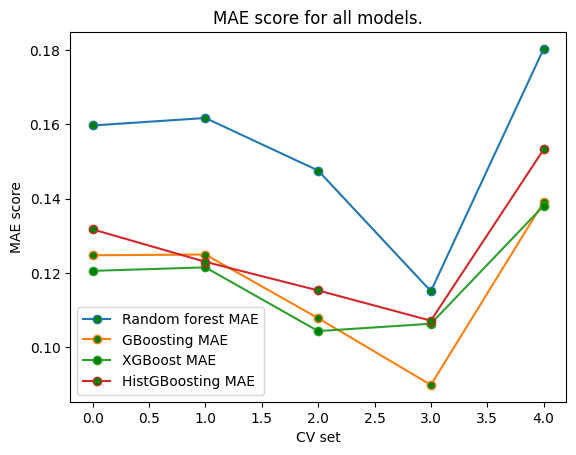

In [ ]:
fig, ax = plt.subplots()
ax.plot(scores11*-1,
        label = 'Random forest MAE',
        marker = 'o',
        markerfacecolor = 'green')
ax.plot(scores21*-1,
        label = 'GBoosting MAE',
        marker = 'o',
        markerfacecolor = 'green')
ax.plot(scores31*-1,
        label = 'XGBoost MAE',
        marker = 'o',
        markerfacecolor = 'green')
ax.plot(scores41*-1,
        label = 'HistGBoosting MAE',
        marker = 'o',
        markerfacecolor = 'green')
ax.set_xlabel('CV set')
ax.set_ylabel('MAE score')
ax.set_title('MAE score for all models.')
ax.legend()
plt.show()

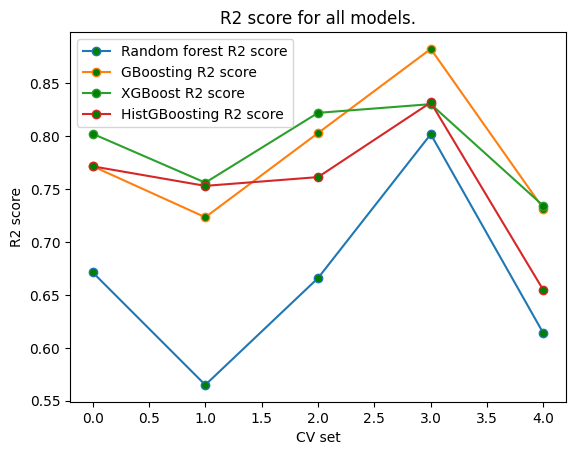

In [ ]:
fig, ax = plt.subplots()
ax.plot(scores10,
        label = 'Random forest R2 score',
        marker = 'o',
        markerfacecolor = 'green')
ax.plot(scores20,
        label = 'GBoosting R2 score',
        marker = 'o',
        markerfacecolor = 'green')
ax.plot(scores30,
        label = 'XGBoost R2 score',
        marker = 'o',
        markerfacecolor = 'green')
ax.plot(scores40,
        label = 'HistGBoosting R2 score',
        marker = 'o',
        markerfacecolor = 'green')
ax.set_xlabel('CV set')
ax.set_ylabel('R2 score')
ax.set_title('R2 score for all models.')
ax.legend()
plt.show()

In [ ]:
hyper_param_tuned_mae = [-grid_search1.best_score_, -grid_search2.best_score_, -grid_search3.best_score_, -grid_search4.best_score_]
hyper_param_tuned_r2 = [best_r21, best_r22, best_r23, best_r24]

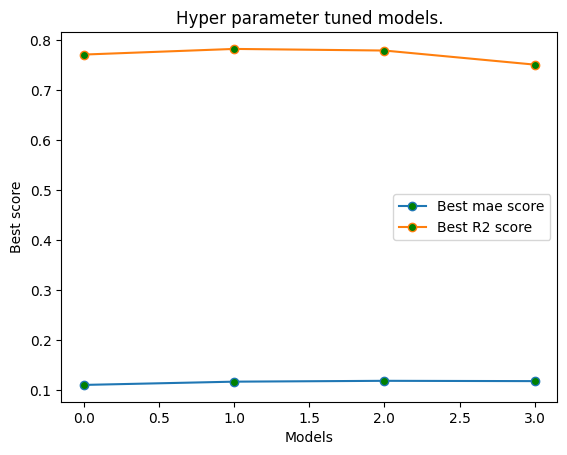

In [ ]:
fig, ax = plt.subplots()
ax.plot(hyper_param_tuned_mae,
        label = 'Best mae score',
        marker = 'o',
        markerfacecolor = 'green')
ax.plot(hyper_param_tuned_r2,
        label = 'Best R2 score',
        marker = 'o',
        markerfacecolor = 'green')
ax.set_xlabel('Models')
ax.set_ylabel('Best score')
ax.set_title('Hyper parameter tuned models.')
ax.legend()
plt.show()

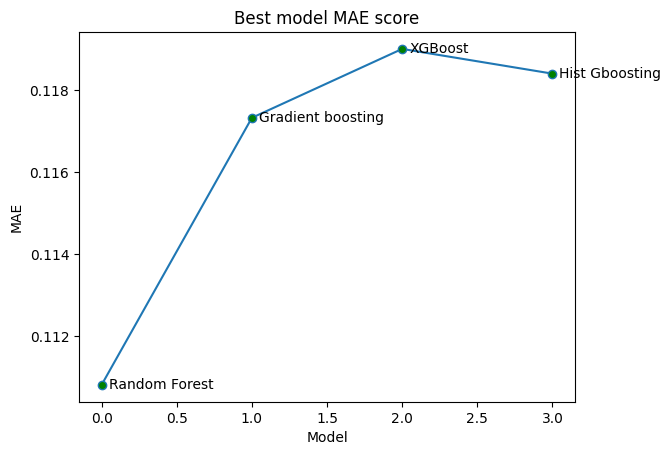

In [ ]:
names = ['Random Forest', 'Gradient boosting', 'XGBoost', 'Hist Gboosting']

fig, ax = plt.subplots()
ax.plot(hyper_param_tuned_mae, label='Best mae score', marker='o', mfc='green')

for i, val in enumerate(hyper_param_tuned_mae):
    label_text = names[i]
    ax.annotate(label_text, (i, val), xytext=(5, -3),
                textcoords="offset points")

ax.set(xlabel='Model', ylabel='MAE')
ax.set_title('Best model MAE score')
plt.show()

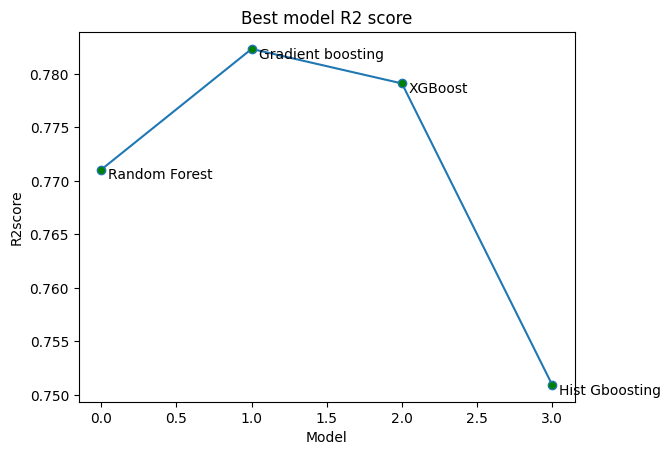

In [ ]:
names = ['Random Forest', 'Gradient boosting', 'XGBoost', 'Hist Gboosting']

fig, ax = plt.subplots()
ax.plot(hyper_param_tuned_r2, label='Best R2 score', marker='o', mfc='green')

for i, val in enumerate(hyper_param_tuned_r2):
    label_text = names[i]
    ax.annotate(label_text, (i, val), xytext=(5, -7),
                textcoords="offset points")

ax.set(xlabel='Model', ylabel='R2score')
ax.set_title('Best model R2 score')
plt.show()

In [ ]:
import shap

def plot_feature_importance(model, feature_names):
    importances = pd.Series(model.feature_importances_, index=feature_names)
    importances.nlargest(10).plot(kind='barh')
    plt.title("Top 10 Feature Importances")
    plt.show()

def plot_shap_summary(model, X_train):
    explainer = shap.Explainer(model)
    shap_values = explainer(X_train)
    shap.summary_plot(shap_values, X_train)

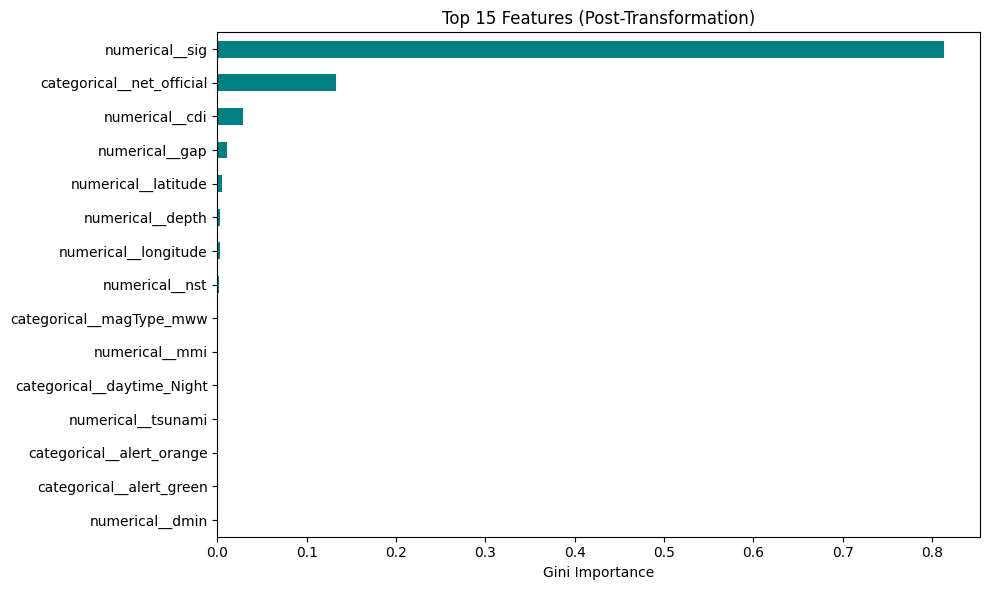

In [ ]:
def plot_pipeline_importance(pipeline):
    model = pipeline[-1]
    try:
        feature_names = pipeline[:-1].get_feature_names_out()
    except:
        print("Could not auto-extract feature names; using generic labels.")
        feature_names = [f"Feature {i}" for i in range(len(model.feature_importances_))]

    importances = pd.Series(model.feature_importances_, index=feature_names)
    plt.figure(figsize=(10, 6))
    importances.nlargest(15).sort_values().plot(kind='barh', color='teal')
    plt.title("Top 15 Features (Post-Transformation)")
    plt.xlabel("Gini Importance")
    plt.tight_layout()
    plt.show()

plot_pipeline_importance(am1)

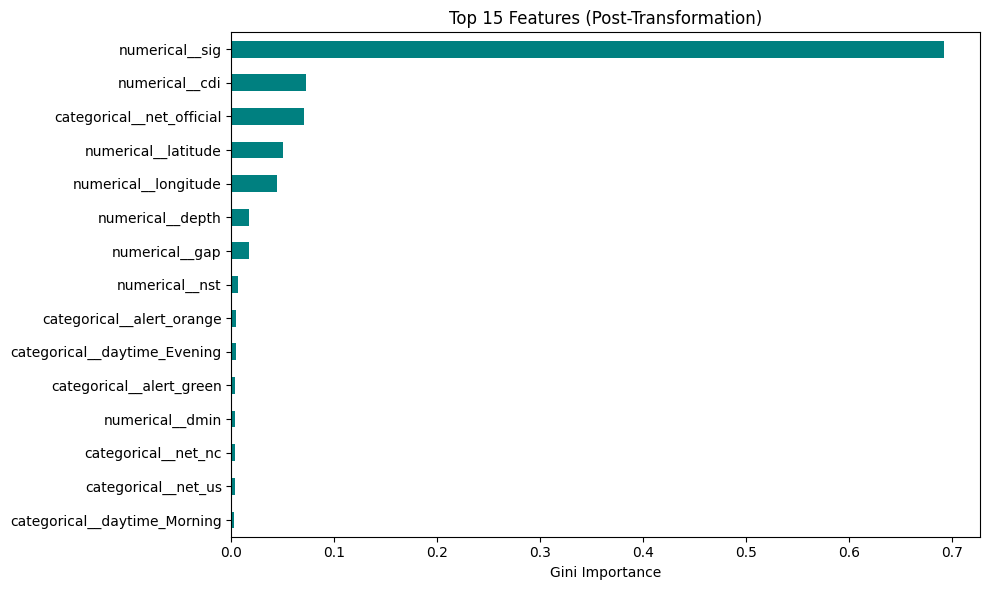

In [ ]:
plot_pipeline_importance(am2)

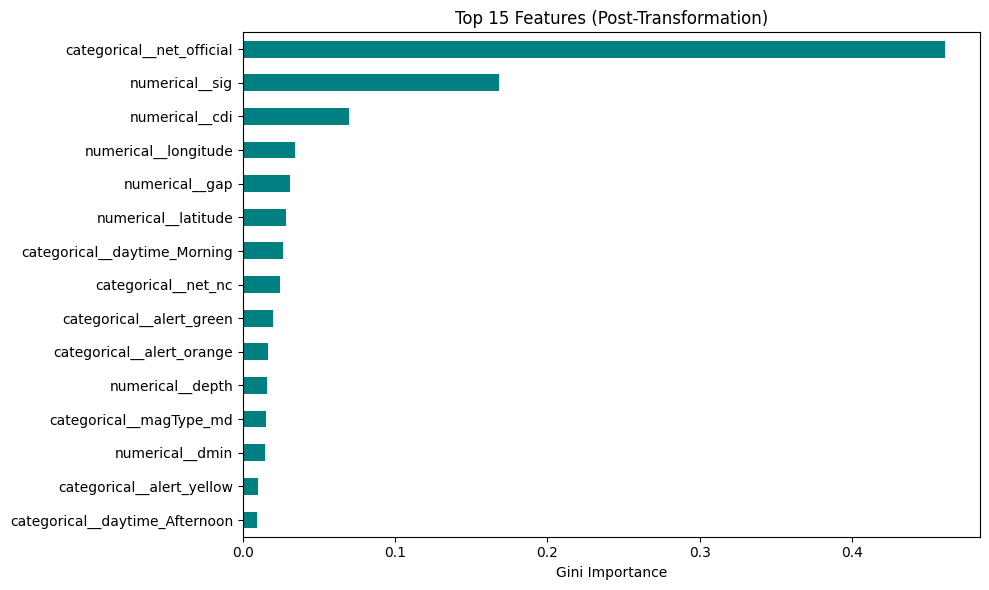

In [ ]:
plot_pipeline_importance(am3)

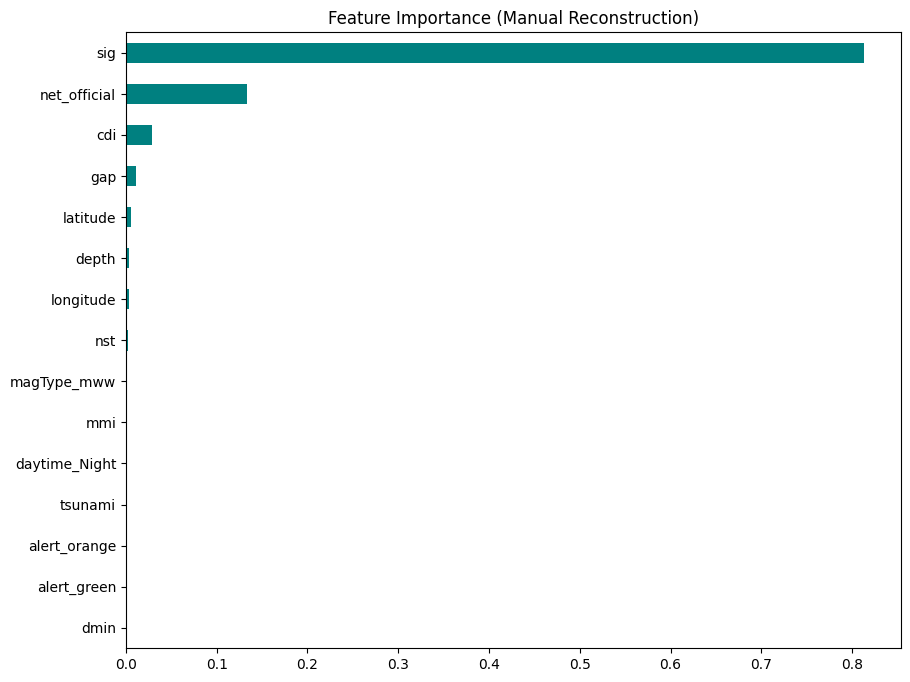

In [ ]:
preprocessor = am1.named_steps['preprocess']
model = am1.named_steps['random forest']
numeric_names = list(x_n.columns)
cat_pipeline = preprocessor.named_transformers_['categorical']
ohe_step = cat_pipeline.named_steps['encoder']
categorical_names = list(ohe_step.get_feature_names_out(x_c.columns))
feature_names = numeric_names + categorical_names
if len(feature_names) != len(model.feature_importances_):
    print(f"Error: Names ({len(feature_names)}) don't match Importance values ({len(model.feature_importances_)})")
else:
    importances = pd.Series(model.feature_importances_, index=feature_names)
    plt.figure(figsize=(10, 8))
    importances.nlargest(15).sort_values().plot(kind='barh', color='teal')
    plt.title("Feature Importance (Manual Reconstruction)")
    plt.show()

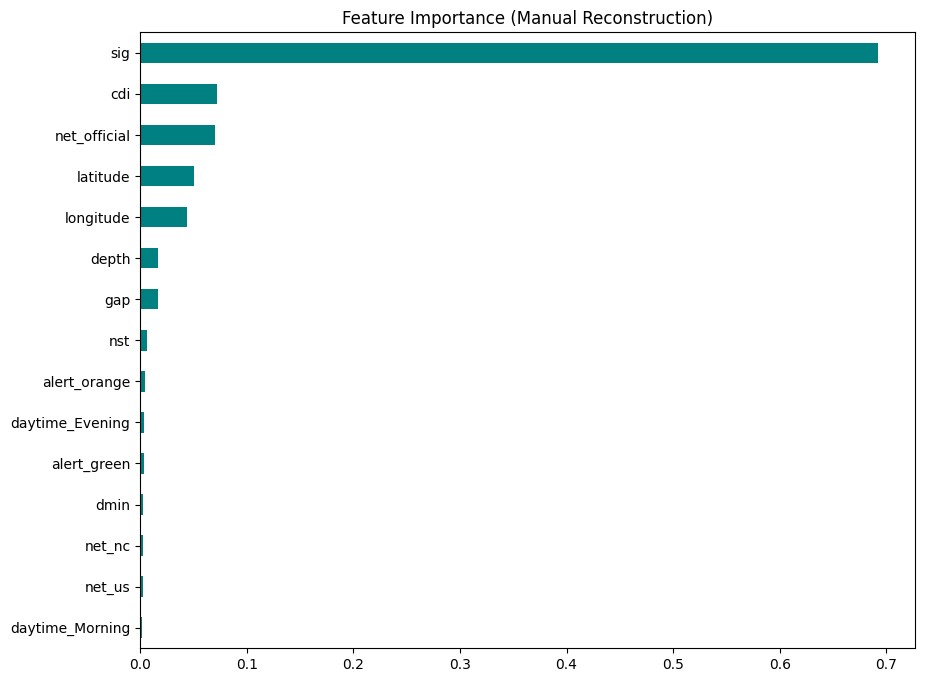

In [ ]:
preprocessor = am2.named_steps['preprocess']
model = am2.named_steps['gradient boosting']
numeric_names = list(x_n.columns)
cat_pipeline = preprocessor.named_transformers_['categorical']
ohe_step = cat_pipeline.named_steps['encoder']
categorical_names = list(ohe_step.get_feature_names_out(x_c.columns))
feature_names = numeric_names + categorical_names
if len(feature_names) != len(model.feature_importances_):
    print(f"Error: Names ({len(feature_names)}) don't match Importance values ({len(model.feature_importances_)})")
else:
    importances = pd.Series(model.feature_importances_, index=feature_names)
    plt.figure(figsize=(10, 8))
    importances.nlargest(15).sort_values().plot(kind='barh', color='teal')
    plt.title("Feature Importance (Manual Reconstruction)")
    plt.show()

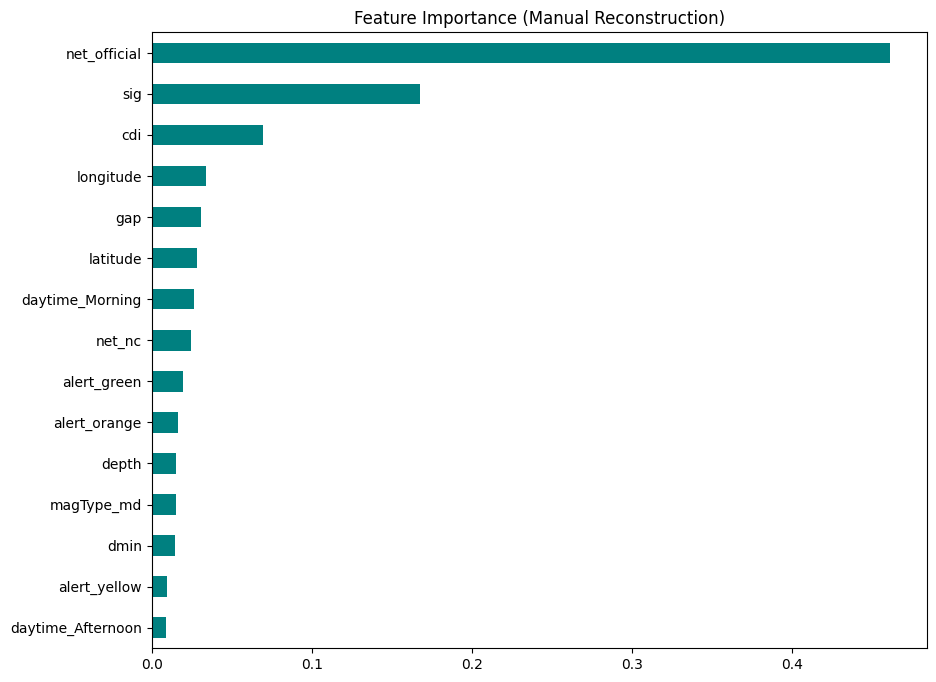

In [ ]:
preprocessor = am3.named_steps['preprocess']
model = am3.named_steps['xgboost']
numeric_names = list(x_n.columns)
cat_pipeline = preprocessor.named_transformers_['categorical']
ohe_step = cat_pipeline.named_steps['encoder']
categorical_names = list(ohe_step.get_feature_names_out(x_c.columns))
feature_names = numeric_names + categorical_names
if len(feature_names) != len(model.feature_importances_):
    print(f"Error: Names ({len(feature_names)}) don't match Importance values ({len(model.feature_importances_)})")
else:
    importances = pd.Series(model.feature_importances_, index=feature_names)
    plt.figure(figsize=(10, 8))
    importances.nlargest(15).sort_values().plot(kind='barh', color='teal')
    plt.title("Feature Importance (Manual Reconstruction)")
    plt.show()

In [ ]:
model = am1.named_steps['random forest']

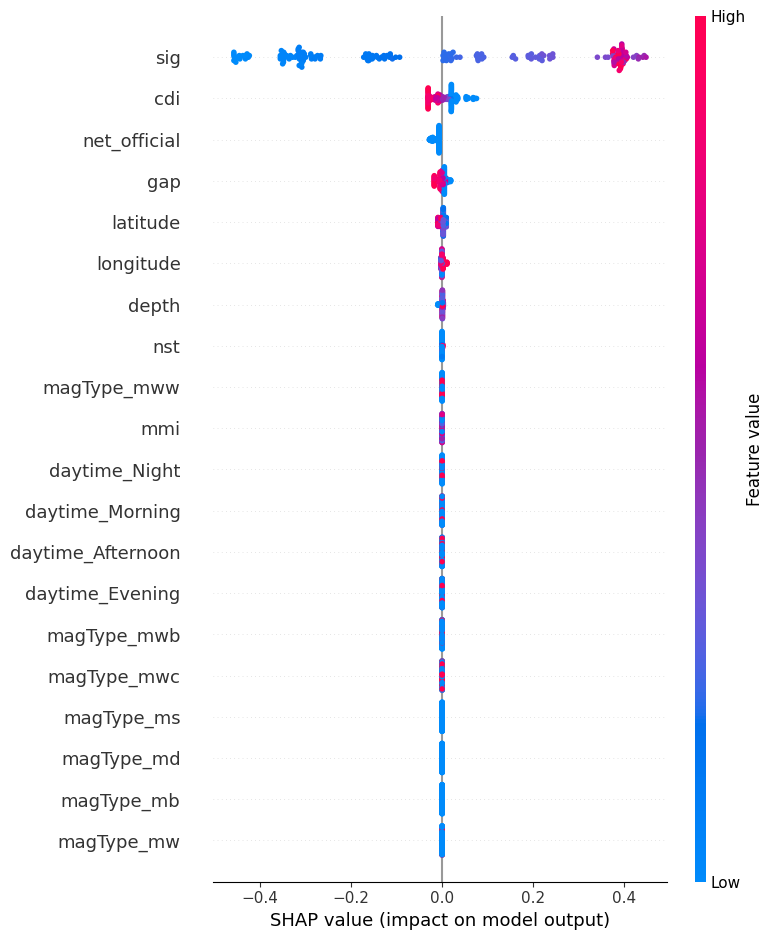

In [ ]:
xtest_transformed = preprocessor.transform(xtest)

xtest_df = pd.DataFrame(
    xtest_transformed.toarray() if hasattr(xtest_transformed, "toarray") else xtest_transformed,
    columns=feature_names
)
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(xtest_df)
shap.summary_plot(shap_values, xtest_df)

In [ ]:
model = am2.named_steps['gradient boosting']

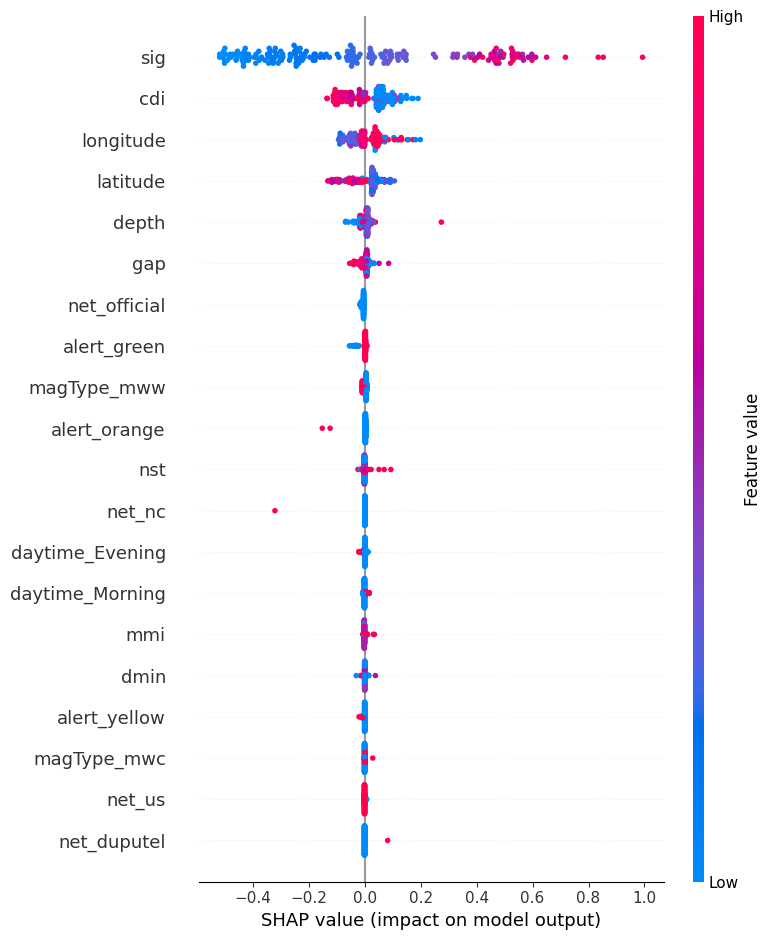

In [ ]:
xtest_transformed = preprocessor.transform(xtest)

xtest_df = pd.DataFrame(
    xtest_transformed.toarray() if hasattr(xtest_transformed, "toarray") else xtest_transformed,
    columns=feature_names
)
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(xtest_df)
shap.summary_plot(shap_values, xtest_df)

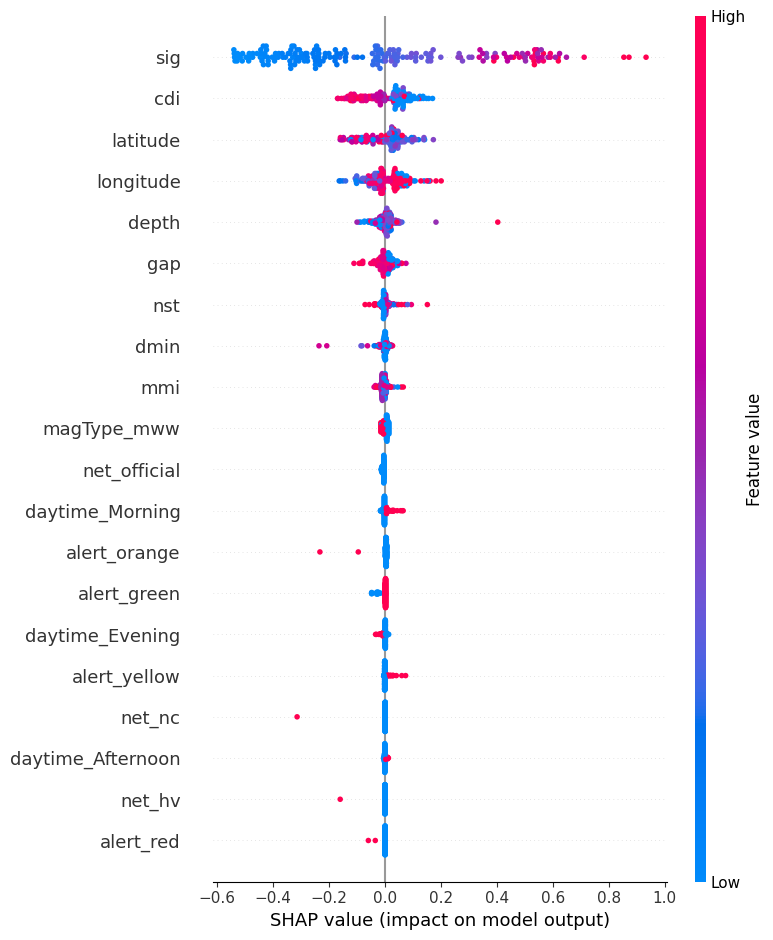

In [ ]:
model_step = am3.named_steps['xgboost']
xtest_transformed = preprocessor.transform(xtest)

xtest_df = pd.DataFrame(
    xtest_transformed.toarray() if hasattr(xtest_transformed, "toarray") else xtest_transformed,
    columns=feature_names
)

explainer = shap.TreeExplainer(model_step)
shap_values = explainer.shap_values(xtest_df)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, xtest_df, show=False)
plt.show()

In [ ]:
import joblib

model = joblib.load('random_forest_model.pkl')
if hasattr(model, 'feature_names_in_'):
  print("Your model expects these features in this order: ")
  print(model.feature_names_in_)
else:
  print("No feature names found. Check n_features_in_for the count: ")
  print(model.n_features_in_)

Your model expects these features in this order: 
['cdi' 'mmi' 'alert' 'tsunami' 'sig' 'net' 'nst' 'dmin' 'gap' 'magType'
 'depth' 'latitude' 'longitude' 'daytime']


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/earthquake_1995-2023.csv')

In [ ]:
print((df['depth'].unique()))

[192.955  69.727 171.371  32.571  21.     10.    229.    167.404  35.981
  18.027 210.097 598.467  15.462  43.063 595.854 594.028 105.631  62.603
 209.976 187.589  65.842  22.065 205.681 598.925  20.522  14.497  17.925
 610.671  28.566 105.249  29.     38.     14.     25.    579.     37.
 624.464 660.    630.379  20.     26.943 137.    116.     12.     30.
  33.729 622.73  236.    220.     27.     24.     41.     28.    535.
 110.      8.     33.     19.     13.    165.49   14.27  126.     51.6
 527.      6.      7.     93.     16.7    33.3    20.74   22.79   47.23
  55.14   46.66   35.     11.     43.    246.    301.     13.23   28.93
  43.98   15.     80.     28.37   16.    624.     26.     22.     73.
 533.76  165.    112.      2.7   107.     96.     12.06   57.8   143.
  14.86   18.    577.     12.26  591.     49.    181.     18.98  212.
  46.     57.92  122.57  146.     15.46  267.    145.     66.     63.
  43.21  570.41   60.21   16.56  133.     46.7   540.     17.    461.
  39. 

In [ ]:
import sklearn
print(sklearn.__version__)

1.6.1
